<a href="https://colab.research.google.com/github/cpt0/data201-labs/blob/main/HW/Week9_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [3]:
from ISLP import load_data
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [4]:
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64


In [5]:
# One-hot encode the two text columns using pd this time!
X = pd.get_dummies(carseats.drop(columns='HighSales'), columns=['ShelveLoc', 'Urban','US']).astype(int)
y = carseats['HighSales']

# Hold out 30% of patients for testing. stratify keeps the class mix similar in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)


print(X_train.shape, X_test.shape)

#you can check your sets (X_train, X_test,...)
X_train.head()

(280, 14) (120, 14)


,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Bad,ShelveLoc_Good,ShelveLoc_Medium,Urban_No,Urban_Yes,US_No,US_Yes
340,140,29,0,105,91,43,16,1,0,0,0,1,1,0
119,130,94,8,137,128,64,12,0,0,1,0,1,0,1
350,111,101,17,266,91,63,17,0,0,1,1,0,0,1
217,106,44,0,481,111,70,14,0,0,1,1,0,1,0
101,128,93,0,89,118,34,18,0,0,1,0,1,1,0


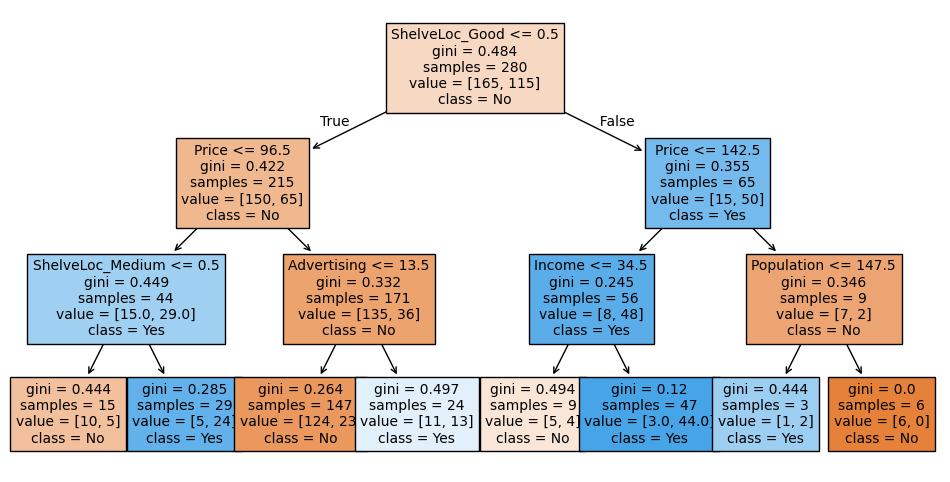

Train accuracy: 0.814
Test accuracy:  0.683


In [6]:
cartree = DecisionTreeClassifier(max_depth=3, random_state=0)
cartree.fit(X_train, y_train)

#figure's size
plt.figure(figsize=(12, 6))

plot_tree(cartree,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'], #here "No" is first, because we set it up to be 0. class_names only changes the labels displayed on the tree. It does not change the model's predictions.
          filled=True, #colors nodes based on their predicted class. Stronger colors indicates greater purity
          fontsize=10)
plt.show()

print('Train accuracy:', round(cartree.score(X_train, y_train), 3))
print('Test accuracy: ', round(cartree.score(X_test, y_test), 3))

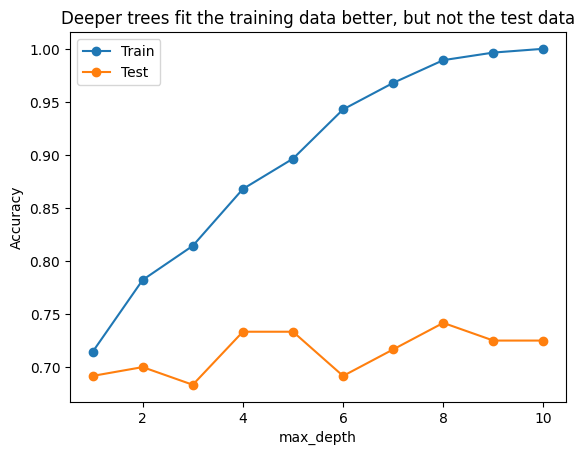

In [7]:
depths = range(1, 11)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.plot(depths, train_acc, marker='o', label='Train')
plt.plot(depths, test_acc, marker='o', label='Test')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.legend()
plt.title('Deeper trees fit the training data better, but not the test data')
plt.show()

# Part 2

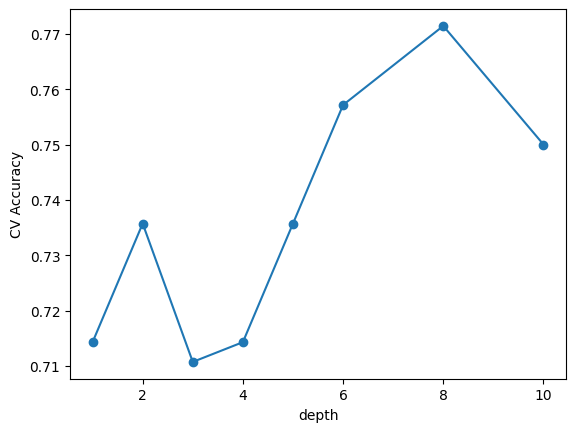

Best depth: 8


In [8]:
treecv= DecisionTreeClassifier(random_state=0)
depths=[1, 2, 3, 4, 5, 6, 8, 10]

cv_acc, n_leaves = [], []


for a in depths:
    m = DecisionTreeClassifier(max_depth=a, random_state=0)
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=5).mean())
    n_leaves.append(m.fit(X_train, y_train).get_n_leaves())

#graph

plt.plot(depths, cv_acc, marker='o', label='Train')
plt.xlabel('depth'); plt.ylabel('CV Accuracy')
plt.show()

best_depth = depths[int(np.argmax(cv_acc))]

print('Best depth:', round(best_depth, 4))

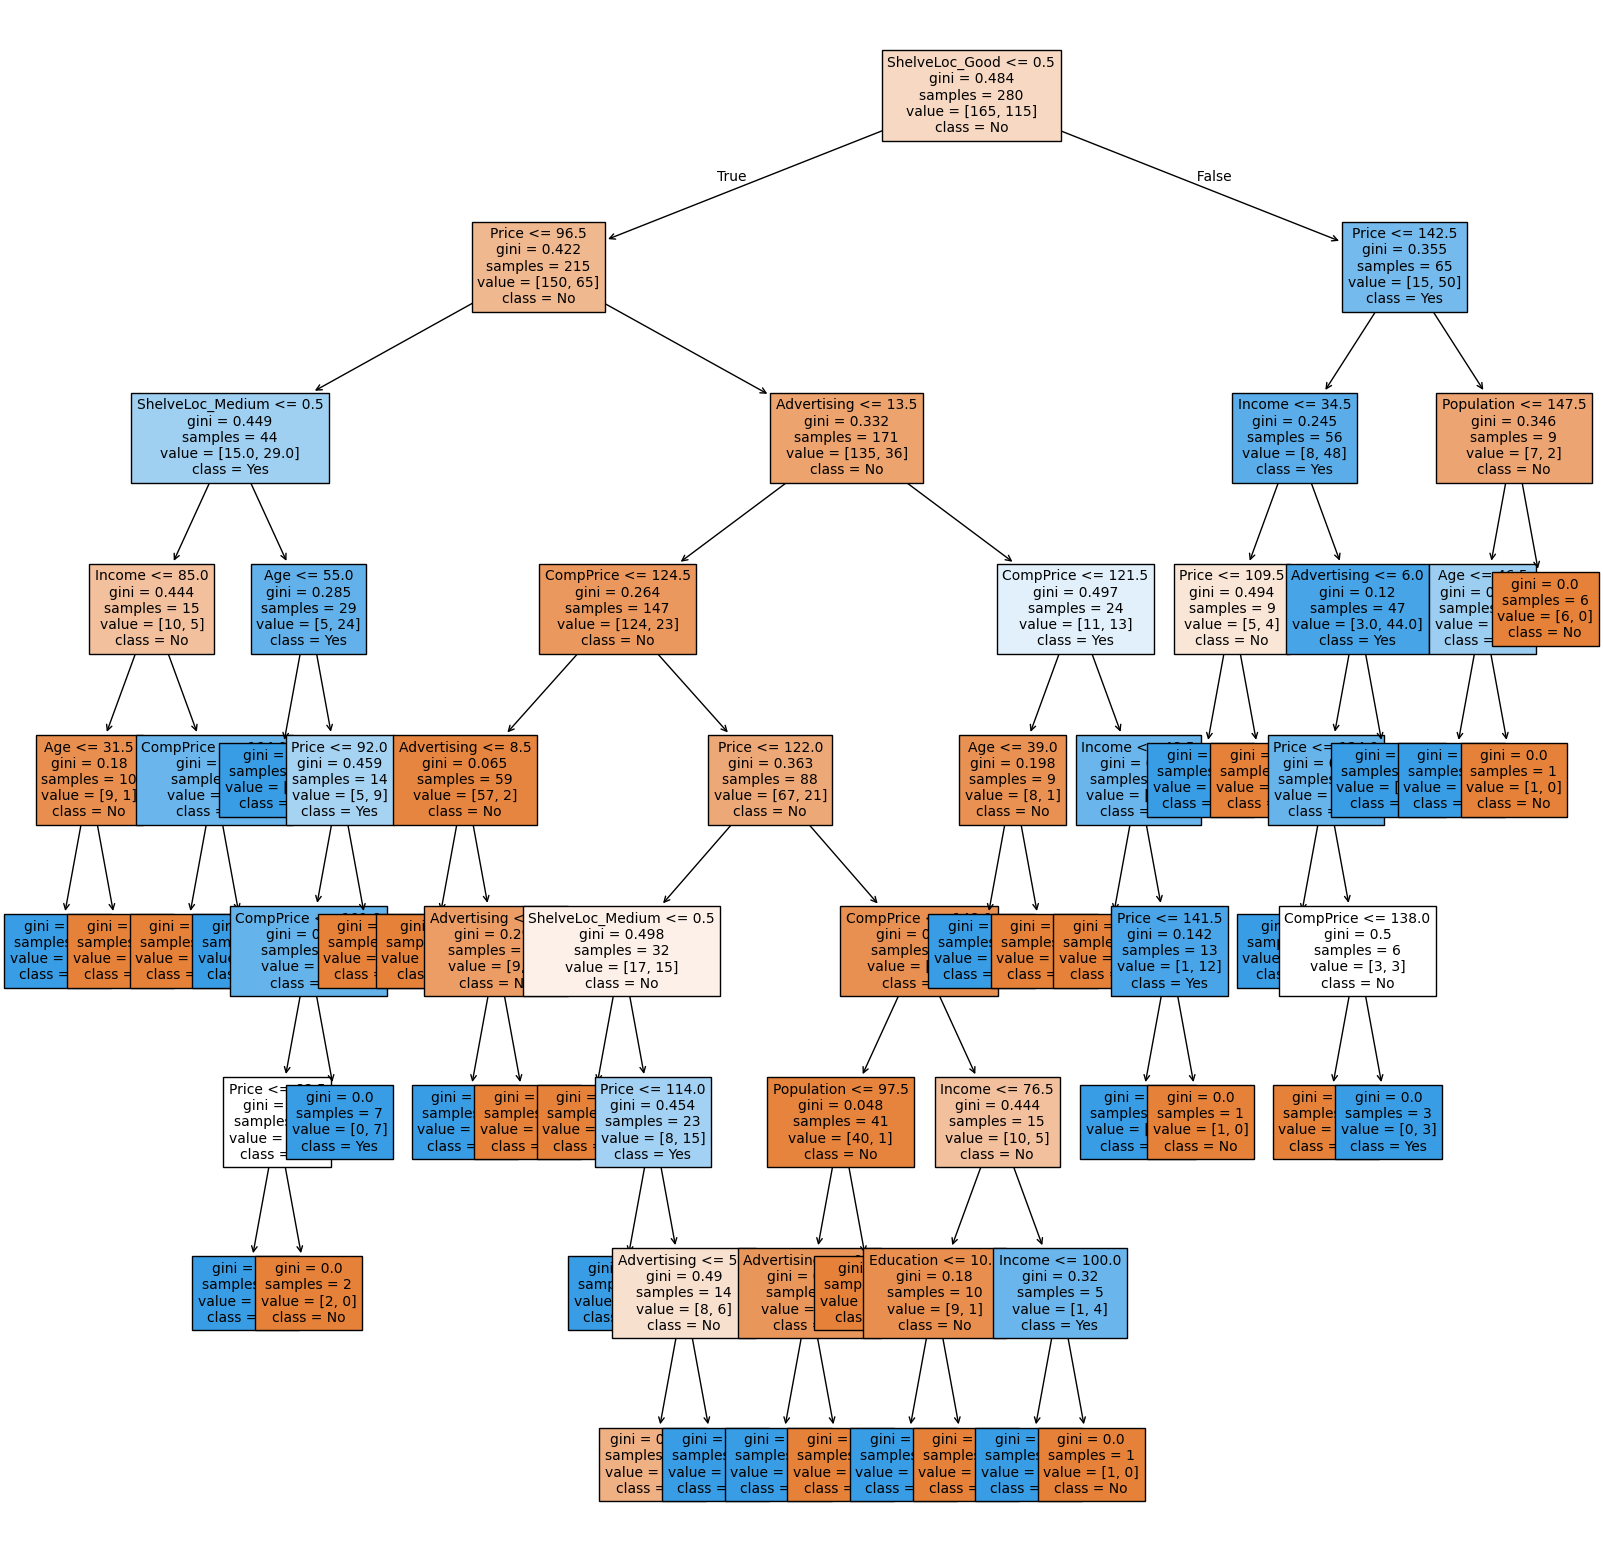

Test accuracy:  0.742


In [9]:
cartree = DecisionTreeClassifier(max_depth=8, random_state=0)
cartree.fit(X_train, y_train)

#figure's size
plt.figure(figsize=(20, 20))

plot_tree(cartree,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'], #here "No" is first, because we set it up to be 0. class_names only changes the labels displayed on the tree. It does not change the model's predictions.
          filled=True, #colors nodes based on their predicted class. Stronger colors indicates greater purity
          fontsize=10)
plt.show()

print('Test accuracy: ', round(cartree.score(X_test, y_test), 3))

# Part 3

1. Interpreting the tree: Which predictor was selected for the first split (root)? What does this split tell us about sales?

ShelveLoc_good was used as the root of the tree this tells us that this predictor is the most important out of all the rest of the predictors.

2. Choosing tree depth: According to your cross-validation graph, which depth performed best? Why should we use cross-validation rather than test accuracy to choose the depth?

The one that performed the best was when the depth was 8. The cross validation score is used rather than the test accuracy because the cross-validation score is based off the training data only. And the CV accuracy is less sensitive than the test accuracy.

3. Overfitting: Does increasing tree depth always improve cross-validation accuracy?
Explain using your graph

No it does not always improve CV accuracy we can see that at max depth 10 the CV accuracy goes down.

## Wrap-up questions

Answer in your own words in a text cell.

1. What does a leaf predict in a classification tree? In a regression tree?


It predicts whether or not the cars have high sales, in a regression tree it looks at the mean of the sales, so we wouldn't make sales into 1s and 0s.

2. Why did the full tree reach 100% training accuracy but do worse on the test set?


Because we are using the whole tree it starts to overfit and gives us a 100% training accuaracy.

3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?


max_depth, and min_samples_leaf. The cross-validation helped me tune the max_depth.

4. Why do we not need to scale features before fitting a tree?
Because the trees look at the features individually.

5. A teammate says "`Age` has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

They're wrong because another feature might carry the same information. They're also wrong because the importance of age is actually 1 not 0.

6. Name one strength and one weakness of a single decision tree that you saw in this lab.

There is not enough randomness, and a strength is that it is efficient to do one tree instead of a lot.